# Quantum Metal A.7 — IMS 2022 workshop chip: three all-to-all coupled qubits with stated targets (Quantcore PDK rebuild)

**What the chip is.** The chip of the Qiskit Metal IMS 2022 workshop,
`docs/circuit-examples/full-design-flow-examples/A.7-IMS-2022-workshop.ipynb` (© IBM / Qiskit Metal contributors,
Apache-2.0, <https://github.com/qiskit-community/qiskit-metal>; spec `docs/designs/metal/A7_ims2022_3q.md`): three
`TransmonPocket6` qubits in a triangle, coupled all-to-all by three λ/2 buses. `Q_0` and `Q_1` are read out through
`CapNInterdigitalTee`s on a short north feedline (two launchpads), `Q_2` through a series `CapNInterdigital` to its
own south launchpad. The tutorial states targets (f_q 4.8 / 5.0 / 5.2 GHz, α −300 MHz, readouts 6.8 / 7.0 / 7.2 GHz,
buses 5.8 / 6.0 / 6.2 GHz) and tunes `Q_0`, `Q_1`, `Bus_01` and `Bus_02` with Q3D-LOM and HFSS-EPR sweeps; this
rebuild uses the **tuned** state (the values at the end of the tutorial). We distribute the rebuild under GPL-3.0.

**This notebook rebuilds it with our library and the Quantcore PDK** (PDK v3, `quantcore_nb_sapphire_v1`): the Metal
components are drawn through the `metal:<Class>` wrapper with the tutorial's tuned options; the chip, the stack, the
junctions, the routes, the netlist and the LOM are ours.

| | Qiskit Metal tutorial | Quantcore PDK rebuild |
|---|---|---|
| chip | `DesignPlanar` 6 × 6 mm centred on (0, 0) | the 7.5 × 7.5 mm Quantcore die with the QCT frame, the source's 6 × 6 mm area centred in it (`box=(-750, -750, 6750, 6750)`) |
| substrate | silicon 750 µm, εr 11.45 (Metal default) | sapphire 650 µm, εr 10.25 (LOM and FEM) |
| launchpads | 3 `LaunchpadWirebond`s at the 6 mm chip's edge (outer edge 990 µm from the 7.5 mm die edge) | the same pads, moved to **100 µm** (`frame.pad_edge`) from the die edge (PDK pad rule) |
| junctions | Metal junction line, `hfss_inductance` 14.9 / 13.9 / 14.0 nH (tuned) | Quantcore Nb/AlOx/Nb trilayer junctions **sized for the stated targets** 4.8 / 5.0 / 5.2 GHz: L_J 15.3 / 14.6 / 14.6 nH, R_n ≈ 98–102 kΩ (outside the 40–50 kΩ window: flagged) |
| cheese | Metal's GDS cheese, set explicitly: 3 µm squares every 50 µm, `no_cheese.buffer` 40 µm | the original's Metal rule, drawn by the build (chip `cheese` = `metal_cheese_rule(buffer=40, size=3, pitch=50)`) |
| routes | `RouteMeander` buses 9550 / 9350 / 9700 µm, readouts 8800 / 8500 / 8300 µm, `RoutePathfinder` feedline | qcc meanders / serpentines of the same lengths on the same pins (turn radius 99 µm = Metal's fillet), qcc `cpw` feedline |
| placement | as drawn | content centred in the die |

**Kept exactly:** the three qubits with the tuned options (`pad_gap` 28 µm on `Q_0`/`Q_1`; readout pads 100 × 22 /
100 × 20 µm; bus pads 135 / 130 µm where tuned, else 60 × 10 µm), the tees and the series cap (Metal defaults), the
three launchpads and their positions along the edges, every route's end pins and total length, the 10/6 µm CPW, the
99 µm fillet and all the stated targets.

**Simplified:** the readouts are laid out as serpentines through waypoints (200 µm run pitch, as Metal's meander
spacing) and `Bus_02`/`Bus_12` as qcc meanders on one vertical segment; `Bus_01` meanders between the qubits as in
the source. Metal's `RouteMeander`s with jogs and asymmetry give different footprints with the same end points and
lengths.

The notebook goes step by step: PDK → die → pads → components → routes → centring → DRC → netlist → LOM →
FEM job → results back → one change re-simulated → fab export → snapshots → summary.

## 1 · Setup

The imports, the output folder and the `LIVE` switch: with KLayout open (the default), every step below is pushed to
the KLayout window as you run it; with `QCC_LIVE=0` the notebook builds headless and only writes files. `_common`
holds the small helpers the design notebooks share (tables, snapshots, the PDK placement and fab helpers).

In [1]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK placement and fab helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction
from quantcore_circuits.lom.simulate import simulate
from quantcore_circuits.pdk import get_pdk

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
OUT = Path("examples/designs/metal")             # this notebook's design JSON and PNG snapshots
from quantcore_circuits.circuit.bridges import size_junction


def pad(loc_w, loc_h, width, gap):
    """TransmonPocket6 connection pad (Metal options)."""
    return {"loc_W": loc_w, "loc_H": loc_h, "pad_width": width, "pad_gap": gap}


def serp(start, ends, pitch, vertical=False):
    """Serpentine waypoints from ``start``: runs to each coordinate in ``ends`` (x for horizontal runs, y for vertical
    ones), stepping ``pitch`` between runs; the last run continues to the next waypoint the caller adds."""
    x, y = start
    pts = [(x, y)]
    for i, e in enumerate(ends):
        if vertical:
            y = e
            pts.append((x, y))
            x += pitch
        else:
            x = e
            pts.append((x, y))
            y += pitch
        pts.append((x, y))
    return pts

## 2 · The Quantcore PDK this chip uses

The rebuild takes every process fact from the PDK (`get_pdk()`), not from the source: the stack the LOM and the FEM
jobs use, the die frame, where pads go, which junction is drawn, the cheese and the 3/0 keep-outs. For this chip that means: the standard 7.5 mm die with the QCT frame; the three launchpads go 100 µm from the north and south edges; each qubit's trilayer junction is sized for the tutorial's target (and flagged where that leaves the R_n window); the cheese is the original's (Metal's GDS cheese, 3 µm squares), drawn by the build instead of the PDK band.

In [2]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

## 3 · The die and its frame

`Designer(name, box=...)` opens an empty chip. The box is the die (µm): the standard **7.5 × 7.5 mm** Quantcore die,
with the source's 6 × 6 mm chip area centred in it, so `P(x, y) = (x + 3000, y + 3000)` maps a Metal position (its
chip is centred on (0, 0)) onto ours unchanged. The PDK draws the **QCT frame**: L dicing markers in the four corners
(1000/0), a 3 × 3 alignment grid in each corner area (1001/0), the chip boundary (100/0) and the device ID
`name_chip` on a free edge (optional: no free edge, no ID).

**Cheese: the original's.** The source exports its GDS with Metal's cheese on (step 14), so the original's cheese wins over the PDK band: `chip={"cheese": metal_cheese_rule(buffer=40, size=3, pitch=50)}` hands the build Metal's rule (3 µm squares every 50 µm, 40 µm clear of every etched shape, none within 200 µm of the die edge), and the build draws it instead of the band (`_common.metal_cheese_rule`). The tutorial's targets are attached to the design here
(`d.targets`): the DRC checks them against the PDK band and the LOM tables show them in brackets.

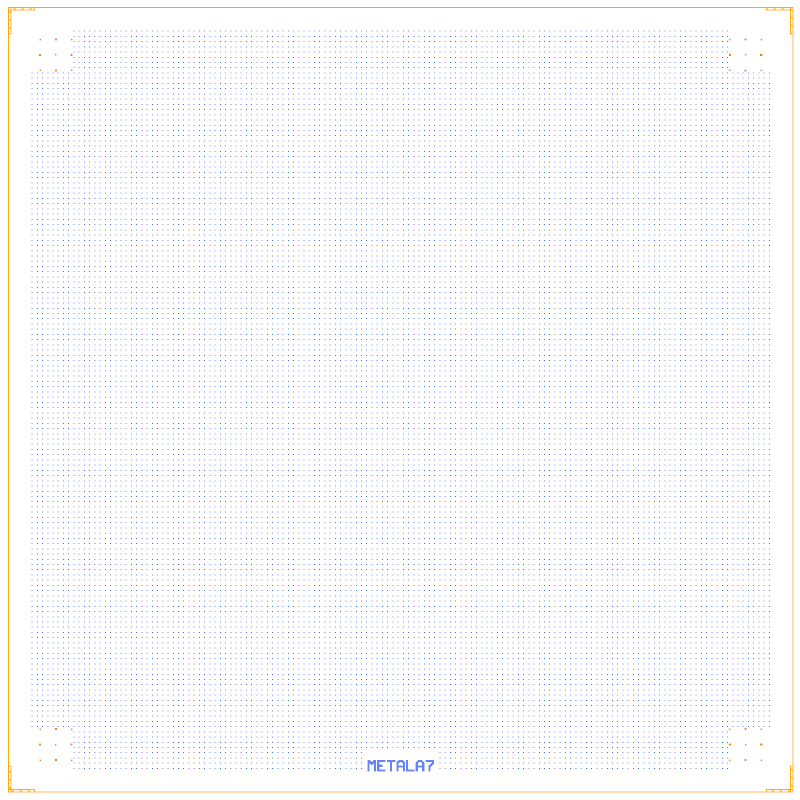

WindowsPath('examples/designs/metal/a7_ims2022_3q_step_die.png')

In [3]:
d = Designer("a7_ims2022_3q", box=(-750, -750, 6750, 6750), chip={"name_chip": "MetalA7", "cheese": metal_cheese_rule(buffer=40, size=3, pitch=50)},
             live=LIVE)
X0, Y0 = 3000, 3000                              # Metal's 6 × 6 mm chip is centred on (0, 0)
P = lambda x, y: (X0 + x, Y0 + y)                # Metal µm → Designer µm
R = 99                                           # Metal fillet
TARGETS = {"Q_0": {"f_q_GHz": 4.8, "alpha_MHz": -300}, "Q_1": {"f_q_GHz": 5.0, "alpha_MHz": -300},
           "Q_2": {"f_q_GHz": 5.2, "alpha_MHz": -300},
           "Readout_0": {"f_GHz": 6.8}, "Readout_1": {"f_GHz": 7.0}, "Readout_2": {"f_GHz": 7.2},
           "Bus_01": {"f_GHz": 5.8}, "Bus_02": {"f_GHz": 6.0}, "Bus_12": {"f_GHz": 6.2}}   # tutorial targets
d.targets(**TARGETS)
rebuild(d)                                       # build the empty die (a no-op when LIVE: it is already built)
snap(d, OUT / "a7_ims2022_3q_step_die.png", size=(800, 800), width=400)

## 4 · Pads: the PDK pad rule

The tutorial puts its three launchpads at the edge of its 6 × 6 mm chip: two on the north side for the `Q_0`/`Q_1`
feedline, one on the south side for `Q_2`. On the 7.5 mm die that leaves their outer edge 990 µm from the die edge.
In the Quantcore PDK the outer edge of every bond pad's etch sits **`frame.pad_edge` = 100 µm from the die
edge**: `edge="n"` / `"s"` slides each pad perpendicular to that edge until it is there; its position along the edge
is kept, so the feedline and `Q_2`'s pad line, which leave the pads along their axis, only get longer. The table
measures it on the built layout.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| Launch_Readout_Q_0 | `metal:LaunchpadWirebond` | n | 100.0 | ✓ |
| Launch_Readout_Q_1 | `metal:LaunchpadWirebond` | n | 100.0 | ✓ |
| Launch_Readout_Q_2 | `metal:LaunchpadWirebond` | s | 100.0 | ✓ |

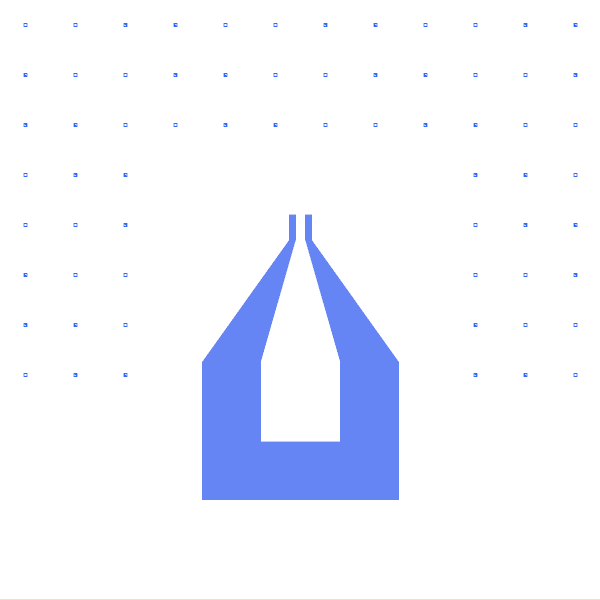

WindowsPath('examples/designs/metal/a7_ims2022_3q_step_pads.png')

In [4]:
with d.batch():
    l0 = d.add("Launch_Readout_Q_0", "metal:LaunchpadWirebond", at=P(-2000, 2500), rot=-90, edge="n")
    l1 = d.add("Launch_Readout_Q_1", "metal:LaunchpadWirebond", at=P(2000, 2500), rot=-90, edge="n")
    l2 = d.add("Launch_Readout_Q_2", "metal:LaunchpadWirebond", at=P(-2000, -2500), rot=90, edge="s")
rebuild(d)
display(Markdown(pads_md(d)))
px, py = port_xy(d, "Launch_Readout_Q_2.tie")
snap(d, OUT / "a7_ims2022_3q_step_pads.png", box=(px - 300, -750, px + 300, -150), size=(600, 600), width=300)

## 5 · Components: the qubits and the readout capacitors

**The qubits.** `metal:TransmonPocket6` is Metal's pocket transmon with up to six connection pads, drawn by the
wrapper with the tutorial's tuned options: 425 µm pads in a 650 µm pocket (`pad_gap` 28 µm on `Q_0`/`Q_1`), a
`readout` pad and two bus pads each (`pad()` builds Metal's `connection_pads` entries).

**The junctions: sized for the targets.** Unlike most Metal examples, this one states its qubit frequencies, so each
Quantcore trilayer junction is sized for its target with the qubit's C_Σ: `size_junction(f_q, C_Σ)` solves the
straight finger on the PDK rule (Nb Δ 1.4 meV, R_n·A 13.5 kΩ·µm², C_J 50 fF/µm²; bent finger 0.6 µm) and
`trilayer_junction(..., lj_nH=)` draws it and returns its L_J and C_J for the LOM and the FEM junction port. C_Σ
(without the junction) comes from this design's LOM before the rebuild. These pockets are small, so 4.8–5.2 GHz needs
L_J ≈ 15 nH, i.e. **R_n ≈ 98–102 kΩ, outside the 40–50 kΩ window**: the DRC flags it (`pdk_rn`); a 45 kΩ junction would
put the qubits at ≈ 7.0–7.3 GHz, still in the 4–8 GHz band. The values are the source's choice, so they are flagged,
not retuned.

**The capacitors.** Two `metal:CapNInterdigitalTee`s sit on the north feedline (each couples a readout to it); a
`metal:CapNInterdigital` is `Q_2`'s series capacitor to its own pad.

Q_0: L_J 15.3055 nH, C_J 6.6 fF, R_n 104 kΩ, fingers 0.22 × 0.6 µm, f_q 4.84 GHz (analytic); R_n 104.2 kΩ is outside the process window 40–50 kΩ (f_q 4.8 GHz with C_Σ 62.2 fF needs E_J/h 10.5 GHz)
Q_1: L_J 14.64 nH, C_J 6.9 fF, R_n 98 kΩ, fingers 0.23 × 0.6 µm, f_q 5.02 GHz (analytic); R_n 98.5 kΩ is outside the process window 40–50 kΩ (f_q 5 GHz with C_Σ 60.8 fF needs E_J/h 11.1 GHz)
Q_2: L_J 14.64 nH, C_J 6.9 fF, R_n 98 kΩ, fingers 0.23 × 0.6 µm, f_q 5.20 GHz (analytic); R_n 98.0 kΩ is outside the process window 40–50 kΩ (f_q 5.2 GHz with C_Σ 56.2 fF needs E_J/h 11.1 GHz)
Q_0 ports: ['bus_01', 'bus_02', 'readout', 'squid_a', 'squid_b'] | tee ports: ['prime_end', 'prime_start', 'second_end'] | cap ports: ['north_end', 'south_end']


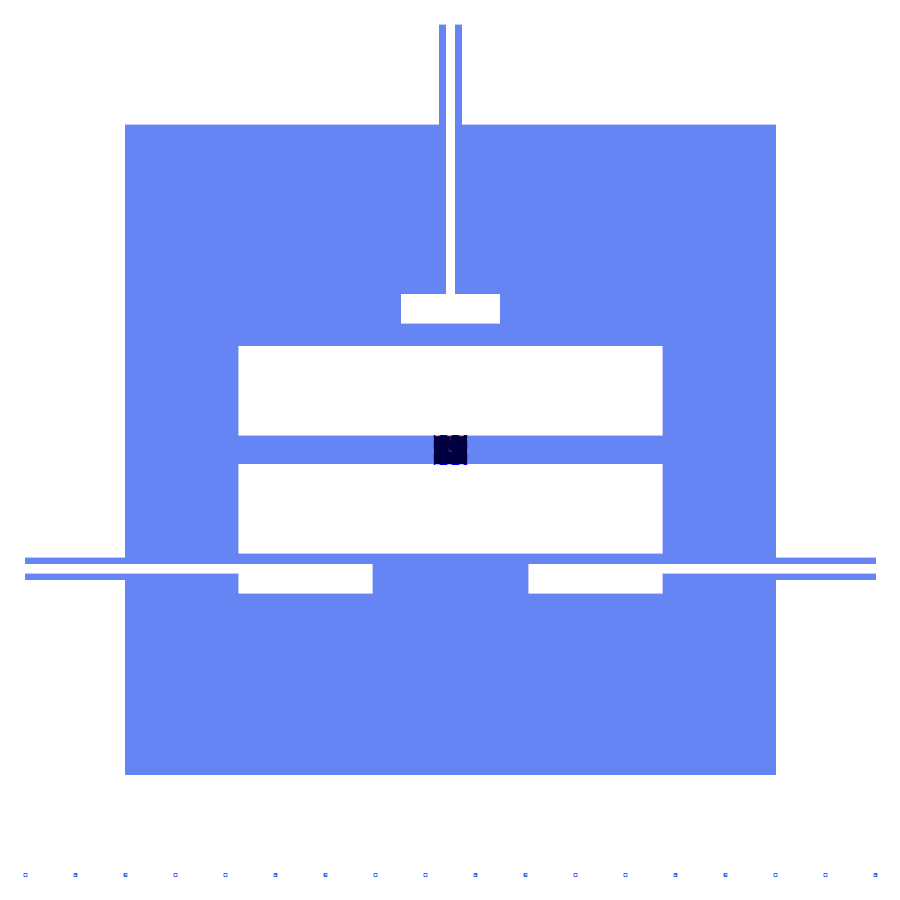

WindowsPath('examples/designs/metal/a7_ims2022_3q_step_parts.png')

In [5]:
# Quantcore trilayer junctions, each sized on the PDK rule (Nb Δ 1.4 meV; R_n·A 13.5 kΩ·µm², C_J 50 fF/µm² assumed) for
# the tutorial's target f_q with the qubit's C_Σ (fF, without the junction) from this design's LOM before the rebuild
# (QuTiP f_q 5.094 / 5.364 / 5.563 GHz with the source's 14.9 / 13.9 / 14.0 nH + 2 fF)
C_SIGMA = {"Q_0": 55.7, "Q_1": 53.9, "Q_2": 49.3}
SIZED = {q: size_junction(TARGETS[q]["f_q_GHz"], c, c_includes_junction=False) for q, c in C_SIGMA.items()}
JJP, JJ = {}, {}
for q, s in SIZED.items():
    JJP[q], JJ[q] = trilayer_junction("metal:TransmonPocket6", lj_nH=s.lj_nH)
    print(f"{q}: L_J {JJ[q]['Lj_nH']} nH, C_J {JJ[q]['Cj_fF']} fF, R_n {s.rn_kohm:.0f} kΩ, fingers {s.finger_width} × "
          f"{s.second_finger_width} µm, f_q {s.f_q_drawn_GHz:.2f} GHz (analytic)" + "".join(f"; {n}" for n in s.notes))
with d.batch():
    pocket = dict(pad_width=425, pocket_height=650)
    q0 = d.add("Q_0", "metal:TransmonPocket6", at=P(-1250, 500), pad_gap=28, junction=JJ["Q_0"], **JJP["Q_0"], **pocket,
               connection_pads={"readout": pad(0, 1, 100, 22), "bus_01": pad(1, -1, 135, 10), "bus_02": pad(-1, -1, 135, 10)})
    q1 = d.add("Q_1", "metal:TransmonPocket6", at=P(1250, 500), pad_gap=28, junction=JJ["Q_1"], **JJP["Q_1"], **pocket,
               connection_pads={"readout": pad(0, 1, 100, 20), "bus_01": pad(-1, -1, 60, 10), "bus_12": pad(1, -1, 130, 10)})
    q2 = d.add("Q_2", "metal:TransmonPocket6", at=P(0, -1350), junction=JJ["Q_2"], **JJP["Q_2"], **pocket,
               connection_pads={"readout": pad(0, -1, 80, 50), "bus_02": pad(-1, 1, 60, 10), "bus_12": pad(1, 1, 60, 10)})
    c2 = d.add("Cap_Readout_Q_2", "metal:CapNInterdigital", at=P(-2000, -2250))
    t0 = d.add("Cap_Readout_Q_0", "metal:CapNInterdigitalTee", at=P(-1500, 2250))
    t1 = d.add("Cap_Readout_Q_1", "metal:CapNInterdigitalTee", at=P(1500, 2250))
print("Q_0 ports:", sorted(q0.ports), "| tee ports:", sorted(t0.ports), "| cap ports:", sorted(c2.ports))
qx, qy = P(-1250, 500)
snap(d, OUT / "a7_ims2022_3q_step_parts.png", box=(qx - 450, qy - 450, qx + 450, qy + 450), size=(900, 900), width=360)

## 6 · Routes: feedline, buses and readouts

- **Feedline:** north launchpad → tee 0 → tee 1 → north launchpad, three `cpw` routes; `Q_2`'s capacitor joins its
  south pad with a short straight (Metal's `RouteStraight`).
- **Buses:** three fixed-length λ/2 meanders (the tuned 9550 / 9350 / 9700 µm): `Bus_01` meanders between `Q_0` and
  `Q_1` as in the source; `Bus_02` and `Bus_12` meander on one vertical segment beside the qubits
  (`meander_segment=3`).
- **Readouts:** λ/2 serpentines through waypoints (runs 200 µm apart, like Metal's 200 µm meander spacing) sized to
  their lengths to 0.01 µm. The router adds one `Meander` for whatever length is left; a few µm left (Readout_2 had 0.9 µm)
  come out as a shallow slanted kink, so the leftover is kept below 0.01 µm and the serpentine looks clean.
- **Sim groups:** each qubit with its connection pads (the tutorial's Q3D step for the LOM).

route lengths (µm): {'TL_Readout_Q_0': 1523, 'TL_Readout_Q_01': 2900, 'TL_Readout_Q_1': 1523, 'TL_Readout_Q_2': 969, 'Bus_01': 9550, 'Bus_02': 9350, 'Bus_12': 9700, 'Readout_0': 8800, 'Readout_1': 8500, 'Readout_2': 8300}


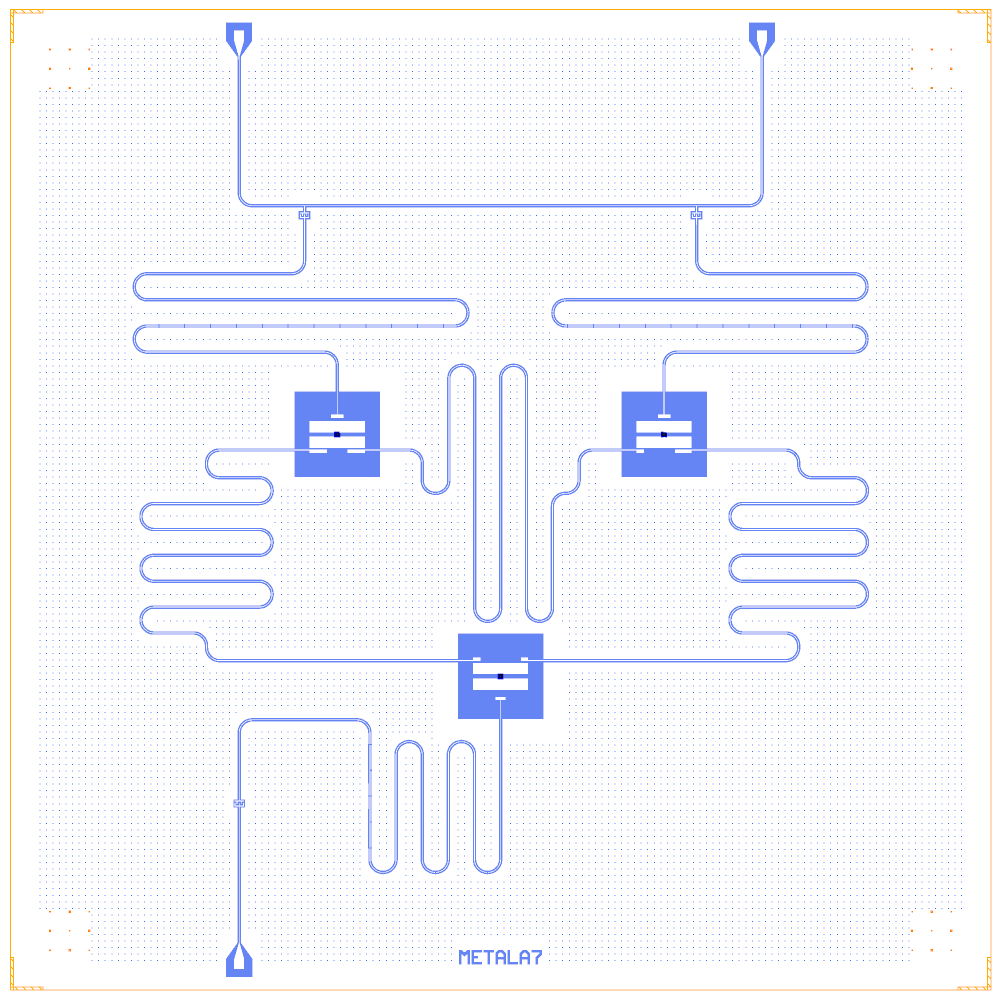

WindowsPath('examples/designs/metal/a7_ims2022_3q_step_routes.png')

In [6]:
with d.batch():
    # feedline: launchpad → tee 0 → tee 1 → launchpad
    d.route("TL_Readout_Q_0", t0.prime_start, l0.tie, r=R, nodes=[(1000, 5250)])
    d.route("TL_Readout_Q_01", t0.prime_end, t1.prime_start)
    d.route("TL_Readout_Q_1", t1.prime_end, l1.tie, r=R, nodes=[(5000, 5250)])
    d.route("TL_Readout_Q_2", c2.south_end, l2.tie, r=30)   # Metal RouteStraight (longer now: the pad is at the edge)
    # buses (tuned lengths): Bus_01 meanders between the qubits, Bus_02 / Bus_12 beside them
    d.route("Bus_01", q0.bus_01, q1.bus_01, meander=9550, r=R, nodes=[(2400, 3381), (2400, 3050), (3600, 3050), (3600, 3381)])
    d.route("Bus_02", q0.bus_02, q2.bus_02, meander=9350, r=R, nodes=[(750, 3381), (750, 1770)]).set(meander_segment=3)   # on the vertical
    d.route("Bus_12", q1.bus_12, q2.bus_12, meander=9700, r=R, nodes=[(5280, 3381), (5280, 1770)]).set(meander_segment=3)
    # λ/2 readouts as serpentines (runs 200 µm apart, like Metal's 200 µm meander spacing), sized to their lengths
    # to 0.01 µm (the router's length-fixing `meander` then has nothing left to draw as a kink)
    d.route("Readout_0", q0.readout, t0.second_end, meander=8800, r=R,
            nodes=serp((1750, 4130), [197.269, 2750, 197.269], 200) + [(1500, 4730)])
    d.route("Readout_1", q1.readout, t1.second_end, meander=8500, r=R,
            nodes=serp((4250, 4130), [5802.731, 3400, 5802.731], 200) + [(4500, 4730)])
    d.route("Readout_2", q2.readout, c2.north_end, meander=8300, r=R,
            nodes=serp((3000, 1000), [149.852, 1150, 149.852, 1150, 149.852], -200, vertical=True) + [(2000, 1317), (1000, 1317)])
# FEM boxes: each qubit with its pads (the tutorial's Q3D step); margins keep every line cut once
for q in ("Q_0", "Q_1", "Q_2"):
    d.sim_group(q, [q], margin_um=50, analyses=["q3d_cmatrix"])
rebuild(d)
print("route lengths (µm):", {k: round(v) for k, v in d.result.route_lengths().items()})
snap(d, OUT / "a7_ims2022_3q_step_routes.png", size=(1000, 1000), width=440)

## 7 · Centre the content and save

The PDK wants the chip content centred in the die. `center_in_die` measures the bounding box of everything placed
(components and routes) and shifts the design so its centre is the die centre (pads keep their 100 µm: they slide
back to the edge along it). The source is laid out about its chip centre and the pads now span the die in y, so the
shift is within the 50 µm tolerance (no move). Then the design is saved: the JSON is the deliverable.

In [7]:
shift = center_in_die(d)
rebuild(d)
print("content shifted by", shift, "µm")
DESIGN = d.save(OUT / "a7_ims2022_3q.json")
print(d, "→", DESIGN)

content shifted by (0.0, 0.0) µm
<Designer a7_ims2022_3q: 9 instances, 10 routes, live=False> → examples\designs\metal\a7_ims2022_3q.json


## 8 · DRC

`d.drc()` checks connectivity (every port routed or snapped, route ends resolved), crossings, overlaps, the chip
box and the frame. It has three kinds of findings:
- **errors** (open, short, crossing, outside the chip): the design is broken; there must be none;
- **warnings** (an unused port, two component boxes overlapping): worth a look, often by design;
- **PDK design warnings** (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): the design is valid but leaves a PDK
  margin. They are flagged, never fixed by retuning: the values are the source's.

Expected here: **no errors**, six `dangling_port` warnings (`squid_a` / `squid_b` of the three qubits, the
junctions' attachment points: the qubit cell draws the junction itself, nothing is routed there) and **three PDK
design warnings** `pdk_rn` (`Q_0`/`Q_1`/`Q_2` R_n ≈ 98–102 kΩ: the junctions are sized for the tutorial's 4.8 / 5.0 /
5.2 GHz targets on small pockets, see step 5). No `pad_edge` (the pads are at 100 µm) and no `pdk_fq` (all targets
are inside 4–8 GHz).

`pdk_report(d)` sums up the PDK side: the cheese source, how far the content centre is from the die centre, the
junction types and the design warnings.

In [8]:
rep = d.drc()
display(Markdown(drc_md(rep)))
display(Markdown(pdk_report(d)))

**0 errors · 6 warnings · 3 PDK design warnings** (DRC clean)

| kind | rule | count | first message |
|---|---|---|---|
| warning | `dangling_port` | 6 | Q_0.squid_a is not connected (no route or snap) |
| PDK design warning | `pdk_rn` | 3 | Q_0: junction R_n 102.3 kΩ is outside the PDK window 40–50 kΩ (L_J 15.3055 nH) |

| check | value |
|---|---|
| cheese | the original design's rule (drawn in the build): size 3, gap 47, rows 1000, clearance 40, edge 200 |
| content centre − die centre | (+0, +0) µm |
| junction types | Quantcore Junction × 3 |
| PDK design warnings | 3 (pdk_rn × 3) |
| pdk_rn | Q_0: junction R_n 102.3 kΩ is outside the PDK window 40–50 kΩ (L_J 15.3055 nH) |
| pdk_rn | Q_1: junction R_n 97.8 kΩ is outside the PDK window 40–50 kΩ (L_J 14.64 nH) |
| pdk_rn | Q_2: junction R_n 97.8 kΩ is outside the PDK window 40–50 kΩ (L_J 14.64 nH) |

## 9 · Netlist and LOM

`d.lom()` turns the layout into a lumped circuit: a `TransmonPocket6` gives two floating pad nodes with the junction
between them, plus a node per connection pad. The buses are λ/2 `TLres` between two pads; `Readout_0`/`Readout_1` are
λ/2 (pad → interdigital tee on the feedline between two 50 Ω ports), `Readout_2` is λ/2 (pad → series cap → 50 Ω
port). The port map shows where `Q_0`'s ports landed.

In [9]:
lb = d.lom()
show_netlist(lb)
print({k: v for k, v in lb.port_map.items() if k.startswith(("Q_0.", "Cap_Readout_Q_0."))})

**15 nodes · 55 branches · 0 controls · 0 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `Cap_Readout_Q_0.prime` | `Launch_Readout_Q_0.pad`, `Launch_Readout_Q_1.pad`, `Cap_Readout_Q_0.prime`, `Cap_Readout_Q_1.prime` |
| `Cap_Readout_Q_2.b` | `Launch_Readout_Q_2.pad`, `Cap_Readout_Q_2.south_end` |
| `Q_0.island1` | `Q_0.island1` |
| `Q_0.island2` | `Q_0.island2` |
| `Q_0.readout` | `Q_0.readout`, `Cap_Readout_Q_0.second_end` |
| `Q_0.bus_01` | `Q_0.bus_01`, `Q_1.bus_01` |
| `Q_0.bus_02` | `Q_0.bus_02`, `Q_2.bus_02` |
| `Q_1.island1` | `Q_1.island1` |
| `Q_1.island2` | `Q_1.island2` |
| `Q_1.readout` | `Q_1.readout`, `Cap_Readout_Q_1.second_end` |
| `Q_1.bus_12` | `Q_1.bus_12`, `Q_2.bus_12` |
| `Q_2.island1` | `Q_2.island1` |
| `Q_2.island2` | `Q_2.island2` |
| `Q_2.readout` | `Q_2.readout`, `Cap_Readout_Q_2.north_end` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `Port_Launch_Readout_Q_0` | R | `Cap_Readout_Q_0.prime` – `gnd` | 50 Ω |
| `Port_Launch_Readout_Q_1` | R | `Cap_Readout_Q_0.prime` – `gnd` | 50 Ω |
| `Port_Launch_Readout_Q_2` | R | `Cap_Readout_Q_2.b` – `gnd` | 50 Ω |
| `C_Q_0_1` | C | `Q_0.island1` – `gnd` | 34.8 fF |
| `C_Q_0_2` | C | `Q_0.island2` – `gnd` | 34.8 fF |
| `C_Q_0_12` | C | `Q_0.island1` – `Q_0.island2` | 27.3 fF |
| `J_Q_0` | JJ | `Q_0.island1` – `Q_0.island2` | Lj 15.3 nH, Cj 6.6 fF |
| `Cg_Q_0_readout` | C | `Q_0.island1` – `Q_0.readout` | 10.9 fF |
| `Cf_Q_0_readout` | C | `Q_0.island2` – `Q_0.readout` | 1.1 fF |
| `Cc_Q_0_readout` | C | `Q_0.readout` – `gnd` | 30.9 fF |
| `Cg_Q_0_bus_01` | C | `Q_0.island2` – `Q_0.bus_01` | 18.3 fF |
| `Cf_Q_0_bus_01` | C | `Q_0.island1` – `Q_0.bus_01` | 1.9 fF |
| `Cc_Q_0_bus_01` | C | `Q_0.bus_01` – `gnd` | 32.5 fF |
| `Cg_Q_0_bus_02` | C | `Q_0.island2` – `Q_0.bus_02` | 18.3 fF |
| `Cf_Q_0_bus_02` | C | `Q_0.island1` – `Q_0.bus_02` | 1.9 fF |
| `Cc_Q_0_bus_02` | C | `Q_0.bus_02` – `gnd` | 32.5 fF |
| `C_Q_1_1` | C | `Q_1.island1` – `gnd` | 34.8 fF |
| `C_Q_1_2` | C | `Q_1.island2` – `gnd` | 34.8 fF |
| `C_Q_1_12` | C | `Q_1.island1` – `Q_1.island2` | 27.3 fF |
| `J_Q_1` | JJ | `Q_1.island1` – `Q_1.island2` | Lj 14.6 nH, Cj 6.9 fF |
| `Cg_Q_1_readout` | C | `Q_1.island1` – `Q_1.readout` | 11.3 fF |
| `Cf_Q_1_readout` | C | `Q_1.island2` – `Q_1.readout` | 1.2 fF |
| `Cc_Q_1_readout` | C | `Q_1.readout` – `gnd` | 30.9 fF |
| `Cg_Q_1_bus_01` | C | `Q_1.island2` – `Q_0.bus_01` | 7.59 fF |
| `Cf_Q_1_bus_01` | C | `Q_1.island1` – `Q_0.bus_01` | 0.8 fF |
| `Cc_Q_1_bus_01` | C | `Q_0.bus_01` – `gnd` | 28.4 fF |
| `Cg_Q_1_bus_12` | C | `Q_1.island2` – `Q_1.bus_12` | 17.7 fF |
| `Cf_Q_1_bus_12` | C | `Q_1.island1` – `Q_1.bus_12` | 1.9 fF |
| `Cc_Q_1_bus_12` | C | `Q_1.bus_12` – `gnd` | 32.3 fF |
| `C_Q_2_1` | C | `Q_2.island1` – `gnd` | 34.3 fF |
| `C_Q_2_2` | C | `Q_2.island2` – `gnd` | 34.3 fF |
| `C_Q_2_12` | C | `Q_2.island1` – `Q_2.island2` | 26.2 fF |
| `J_Q_2` | JJ | `Q_2.island1` – `Q_2.island2` | Lj 14.6 nH, Cj 6.9 fF |
| `Cg_Q_2_readout` | C | `Q_2.island2` – `Q_2.readout` | 6.46 fF |
| `Cf_Q_2_readout` | C | `Q_2.island1` – `Q_2.readout` | 0.68 fF |
| `Cc_Q_2_readout` | C | `Q_2.readout` – `gnd` | 30 fF |
| `Cg_Q_2_bus_02` | C | `Q_2.island1` – `Q_0.bus_02` | 7.63 fF |
| `Cf_Q_2_bus_02` | C | `Q_2.island2` – `Q_0.bus_02` | 0.8 fF |
| `Cc_Q_2_bus_02` | C | `Q_0.bus_02` – `gnd` | 28.4 fF |
| `Cg_Q_2_bus_12` | C | `Q_2.island1` – `Q_1.bus_12` | 7.63 fF |
| `Cf_Q_2_bus_12` | C | `Q_2.island2` – `Q_1.bus_12` | 0.8 fF |
| `Cc_Q_2_bus_12` | C | `Q_1.bus_12` – `gnd` | 28.4 fF |
| `C_Cap_Readout_Q_2` | C | `Q_2.readout` – `Cap_Readout_Q_2.b` | 5.26 fF |
| `C_Cap_Readout_Q_2_a` | C | `Q_2.readout` – `gnd` | 19 fF |
| `C_Cap_Readout_Q_2_b` | C | `Cap_Readout_Q_2.b` – `gnd` | 19 fF |
| `C_Cap_Readout_Q_0` | C | `Cap_Readout_Q_0.prime` – `Q_0.readout` | 5.26 fF |
| `C_Cap_Readout_Q_0_second` | C | `Q_0.readout` – `gnd` | 7.4 fF |
| `C_Cap_Readout_Q_1` | C | `Cap_Readout_Q_0.prime` – `Q_1.readout` | 5.26 fF |
| `C_Cap_Readout_Q_1_second` | C | `Q_1.readout` – `gnd` | 7.4 fF |
| `Bus_01` | TLres | `Q_0.bus_01` – `gnd` | lambda/2, 9550 µm, 6.599 GHz |
| `Bus_02` | TLres | `Q_0.bus_02` – `gnd` | lambda/2, 9350 µm, 6.740 GHz |
| `Bus_12` | TLres | `Q_1.bus_12` – `gnd` | lambda/2, 9700 µm, 6.497 GHz |
| `Readout_0` | TLres | `Q_0.readout` – `gnd` | lambda/2, 8800 µm, 7.161 GHz |
| `Readout_1` | TLres | `Q_1.readout` – `gnd` | lambda/2, 8500 µm, 7.414 GHz |
| `Readout_2` | TLres | `Q_2.readout` – `gnd` | lambda/2, 8300 µm, 7.592 GHz |

**Unconnected ports:** none

{'Q_0.squid_a': 'Q_0.island2', 'Q_0.squid_b': 'Q_0.island1', 'Q_0.readout': 'Q_0.readout', 'Q_0.bus_01': 'Q_0.bus_01', 'Q_0.bus_02': 'Q_0.bus_02', 'Cap_Readout_Q_0.prime_start': 'Cap_Readout_Q_0.prime', 'Cap_Readout_Q_0.prime_end': 'Cap_Readout_Q_0.prime', 'Cap_Readout_Q_0.second_end': 'Q_0.readout'}


## 10 · LOM simulation and the tutorial's targets

Each qubit with its readout (and the feedline or its pad); then each bus with the two qubits it joins (QuCat normal
modes, static ZZ from QuTiP). Targets in brackets are the tutorial's (f_q 4.8 / 5.0 / 5.2 GHz, α −300 MHz, readouts
6.8 / 7.0 / 7.2 GHz, buses 5.8 / 6.0 / 6.2 GHz). The junctions are sized for the targets from the analytic C_Σ, so f_q
should land within a few % of them; the readouts and buses are the tutorial's tuned lengths on sapphire with the
analytic pad model, so they sit a few % above target. The tutorial tuned against Q3D C-matrices: the per-qubit Q3D jobs
(step 11) are what `fem_back` replaces the pad estimates with.

In [10]:
feed = ["Launch_Readout_Q_0", "Launch_Readout_Q_1", "TL_Readout_Q_0", "TL_Readout_Q_01", "TL_Readout_Q_1",
        "Cap_Readout_Q_0", "Cap_Readout_Q_1"]
read = {"Q_0+read": ["Q_0", "Readout_0"] + feed, "Q_1+read": ["Q_1", "Readout_1"] + feed,
        "Q_2+read": ["Q_2", "Readout_2", "Cap_Readout_Q_2", "TL_Readout_Q_2", "Launch_Readout_Q_2"]}
results = simulate_groups(d, read)
display(Markdown(groups_md(results, TARGETS)))
buses = {"Q_0+Bus_01+Q_1": ["Q_0", "Bus_01", "Q_1"], "Q_0+Bus_02+Q_2": ["Q_0", "Bus_02", "Q_2"],
         "Q_1+Bus_12+Q_2": ["Q_1", "Bus_12", "Q_2"]}
coupled = simulate_groups(d, buses, max_modes=3)
for g, res in coupled.items():
    display(Markdown(f"**{g}, QuCat normal modes:**\n\n" + modes_md(res)))
display(Markdown("**Static ZZ (QuTiP):**\n\n" + zz_md(coupled)))

| group | qubit | f_q (GHz) | α (MHz) | resonator | f_r (GHz) | κ (MHz) | χ (MHz) |
|---|---|---|---|---|---|---|---|
| Q_0+read | Q_0 | 4.8443 (4.8) | -374 (-300) | Readout_0 | 6.8778 (6.8) | 0.299 | -1.26 |
| Q_1+read | Q_1 | 5.0163 (5) | -382.1 (-300) | Readout_1 | 7.1091 (7) | 0.33 | -1.31 |
| Q_2+read | Q_2 | 5.2048 (5.2) | -418.3 (-300) | Readout_2 | 7.235 (7.2) | 0.689 | -0.563 |

**Q_0+Bus_01+Q_1, QuCat normal modes:**

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| Q_0 | qubit | 5.1736 | 0 | 309.3 | J_Q_0 0.99 |
| Q_1 | qubit | 5.3816 | 0 | 322.7 | J_Q_1 1.00 |
| Bus_01 | resonator | 6.2356 | 0 | 0.0 | Bus_01 0.99 |

**Q_0+Bus_02+Q_2, QuCat normal modes:**

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| Q_0 | qubit | 5.1741 | 0 | 310.1 | J_Q_0 0.99 |
| Q_2 | qubit | 5.5787 | 0 | 346.2 | J_Q_2 1.00 |
| Bus_02 | resonator | 6.3618 | 0 | 0.0 | Bus_02 0.99 |

**Q_1+Bus_12+Q_2, QuCat normal modes:**

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| Q_1 | qubit | 5.3460 | 0 | 312.1 | J_Q_1 0.99, Bus_12 0.01 |
| Q_2 | qubit | 5.5780 | 0 | 344.3 | J_Q_2 0.99 |
| Bus_12 | resonator | 6.1523 | 0 | 0.1 | Bus_12 0.98, J_Q_1 0.01 |

**Static ZZ (QuTiP):**

| group | pair | ZZ (kHz) | neighbours | hybridised |
|---|---|---|---|---|
| Q_0+Bus_01+Q_1 | Q_0-Q_1 | 22.26 | yes | no |
| Q_0+Bus_02+Q_2 | Q_0-Q_2 | 81.15 | yes | no |
| Q_1+Bus_12+Q_2 | Q_1-Q_2 | 36.75 | yes | no |

## 11 · FEM: send the job

The LOM uses analytic capacitance estimates; a finite-element job measures them. `export_sims` cuts each sim group
out of the chip (the box set by `sim_group`), puts ports where lines leave the box and writes a job folder under
`build/jobs/`. Simulation exports never get cheese, and airbridges are dropped unless asked for.

One **Q3D C-matrix** job per qubit with its connection pads (the tutorial's Q3D step for the LOM: island,
pad and bus-pad capacitances). A box around an 8–9 mm readout serpentine would cut the neighbouring meanders, so no
eigenmode job is exported.

`RUN_FEM = False` keeps the notebook fast. Set it to `True` to solve the jobs here: `send_fem_jobs` finds AEDT 2024
R1 (or newer) and solves each Ansys job in a **new batch, non-graphical** AEDT, so an AEDT window you have open is
never touched. The command-line equivalent is `qcc hfss solve build/jobs/<job>`.

In [11]:
jobs = export_sims(DESIGN)
display(Markdown(jobs_md(jobs)))

| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| Q_0 | `build/jobs/a7_ims2022_3q_Q_0_q3d_cmatrix` | 1 · junction · `Q_0.junction`<br>2 · edge · `Bus_01`<br>3 · edge · `Bus_02`<br>4 · edge · `Readout_0` | `Q_0.island2`, `Bus_01`, `Bus_02`, `Readout_0`, `Q_0.island1` |
| Q_1 | `build/jobs/a7_ims2022_3q_Q_1_q3d_cmatrix` | 1 · junction · `Q_1.junction`<br>2 · edge · `Bus_01`<br>3 · edge · `Bus_12`<br>4 · edge · `Readout_1` | `Q_1.island2`, `Bus_01`, `Bus_12`, `Readout_1`, `Q_1.island1` |
| Q_2 | `build/jobs/a7_ims2022_3q_Q_2_q3d_cmatrix` | 1 · junction · `Q_2.junction`<br>2 · edge · `Bus_02`<br>3 · edge · `Bus_12`<br>4 · edge · `Readout_2` | `Q_2.island2`, `Bus_02`, `Bus_12`, `Readout_2`, `Q_2.island1` |

In [12]:
RUN_FEM = False   # True: solve the jobs now in a new batch AEDT (2024 R1 or newer)
if RUN_FEM:
    send_fem_jobs(DESIGN, ['Q_0', 'Q_1', 'Q_2'], run=True)

## 12 · Bring the FEM results back

When a job has been solved, its folder holds `results/results.json`. `fem_back` fills the LOM with the extracted
C-matrix (matched by net name: the job's nets are the LOM's nodes) and lists each capacitance as estimate vs
extracted. Without results it says what would appear; the LOM values above stay the estimates.

In [13]:
filled, back_md = fem_back(lb.model, DESIGN, {f"{g} · q3d": v for g, v in jobs.items()})
display(Markdown(back_md))
for key, fc in filled.items():                   # re-simulate the LOM on the extracted values
    display(Markdown(f"**{key}, LOM on the FEM values:**"))
    display(Markdown(modes_md(simulate(fc))))

No FEM results yet for Q_0 · q3d, Q_1 · q3d, Q_2 · q3d: after a solve, `results/results.json` appears in each job folder and this cell shows the C-matrix (or eigenmode) values next to the LOM estimates; `simulate(filled)` then re-runs the LOM on the extracted values.

## 13 · Iterate: change one property and re-simulate

A design loop in one cell: copy the saved design (`design_copy`: a non-live Designer that never writes over the
JSON), change one property — here `Q_0`'s readout connection pad, 100 → 120 µm wide (the tutorial's own knob for the
readout coupling) — rebuild, re-run the LOM of `Q_0` with its readout and the feedline, and compare. A wider pad
couples the readout more strongly: |χ| grows, and the extra pad capacitance pulls f_q and f_r down slightly; κ,
set by the tee on the feedline, hardly moves.

In [14]:
d2 = design_copy(DESIGN)
d2["Q_0"].set(connection_pads={"readout": pad(0, 1, 120, 22), "bus_01": pad(1, -1, 135, 10),
                               "bus_02": pad(-1, -1, 135, 10)})   # readout pad 100 → 120 µm
after = simulate_groups(d2, {"Q_0+read": read["Q_0+read"]})
display(Markdown(params_delta_md({"Q_0+read": results["Q_0+read"]}, after)))

| parameter | before | after | Δ |
|---|---|---|---|
| `Q_0+read: Q_0.f_q_GHz` | 4.8443 | 4.8147 | -0.02951 |
| `Q_0+read: Q_0.alpha_MHz` | -374 | -368.27 | +5.737 |
| `Q_0+read: Readout_0.chi_MHz` | -1.2622 | -1.7173 | -0.4551 |
| `Q_0+read: Readout_0.f_GHz` | 6.8778 | 6.8635 | -0.01429 |
| `Q_0+read: Readout_0.kappa_MHz` | 0.29893 | 0.29627 | -0.002657 |

## 14 · Build and export

The design JSON saved in step 7 is the deliverable: `qcc build`, `qcc mask` and the KLayout plugin all read it.
The fab export writes only the PDK fab layers (1/0 etch, 3/0 keep-out, 2/0 + 4/0 junction fingers, 50–53/0 spacer,
100/0 chip boundary, 1000/0 + 1001/0 frame markers), with corner rounding and the cheese.

**Cheese: the original wins.** The A.7 notebook exports its GDS with Metal's `QGDSRenderer` and sets the cheese explicitly: `cheese_0_x/y = 3um` squares every `delta_x/y = 50um`, `no_cheese.buffer = 40um`, `cheese.view_in_file = {"main": {1: True}}` (`edge_nocheese` stays at its 200 µm default). So the original *has* cheese, and the precedence rule keeps the original's, not the PDK band. The chip carries Metal's rule as its `cheese` parameter (step 3: `metal_cheese_rule(buffer=40, size=3, pitch=50)` = `{size, gap, rows, clearance, edge}`), so the build draws it into KQC's `ground_grid` layer over the whole free ground inside the frame's design area, clear of the 3/0 keep-outs by the buffer (the 3/0 keep-out already adds the PDK route margin round each CPW, so the holes sit a few µm further from the etch than in Metal). The layout, the snapshots and KLive show it, and `export_fab` / `qcc mask` keep it (`cheese source: build`, no PDK band added).

Command-line equivalents:
- `qcc build examples/designs/metal/<id>.json` (the layout and its KLayout sidecar);
- `qcc mask examples/designs/metal/<id>.json` (the fab file; `--no-cheese`, `--no-round`);
- `qcc sim build examples/designs/metal/<id>.json -g <group> -a q3d_cmatrix` (one FEM job).

In [15]:
print("design file:", DESIGN)
CHEESE = True                                    # export_fab keeps the build's cheese (the original's rule)
display(Markdown(fab_layers_md(d, cheese=CHEESE, rounding=True)))

design file: examples\designs\metal\a7_ims2022_3q.json


| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 15452 |
| 2/0 | JJ_STRAIGHT | 3 |
| 3/0 | M3 | 15446 |
| 4/0 | JJ_BENT | 3 |
| 50/0 | HSQ | 6 |
| 51/0 | SPACER_1 | 6 |
| 52/0 | SPACER_2 | 6 |
| 53/0 | SPACER_3 | 6 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

**Cheese:** source `build`, 15444 holes on the mask.

→ `build/a7_ims2022_3q_fab.oas`

## 15 · Snapshots

The full chip (compare the tutorial's last screenshot); `Q_0` with its three pads; its trilayer junction; the `Q_0`
interdigital tee on the feedline; the **fab mask** beside `Q_2` (1/0 etch with the original's 3 µm Metal cheese on
the free ground, 40 µm clear of the 3/0 keep-outs; the junction layers); and the die frame's south-west corner (dicing L on 1000/0, alignment grid on
1001/0). Positions are read from the design (after the centring shift).

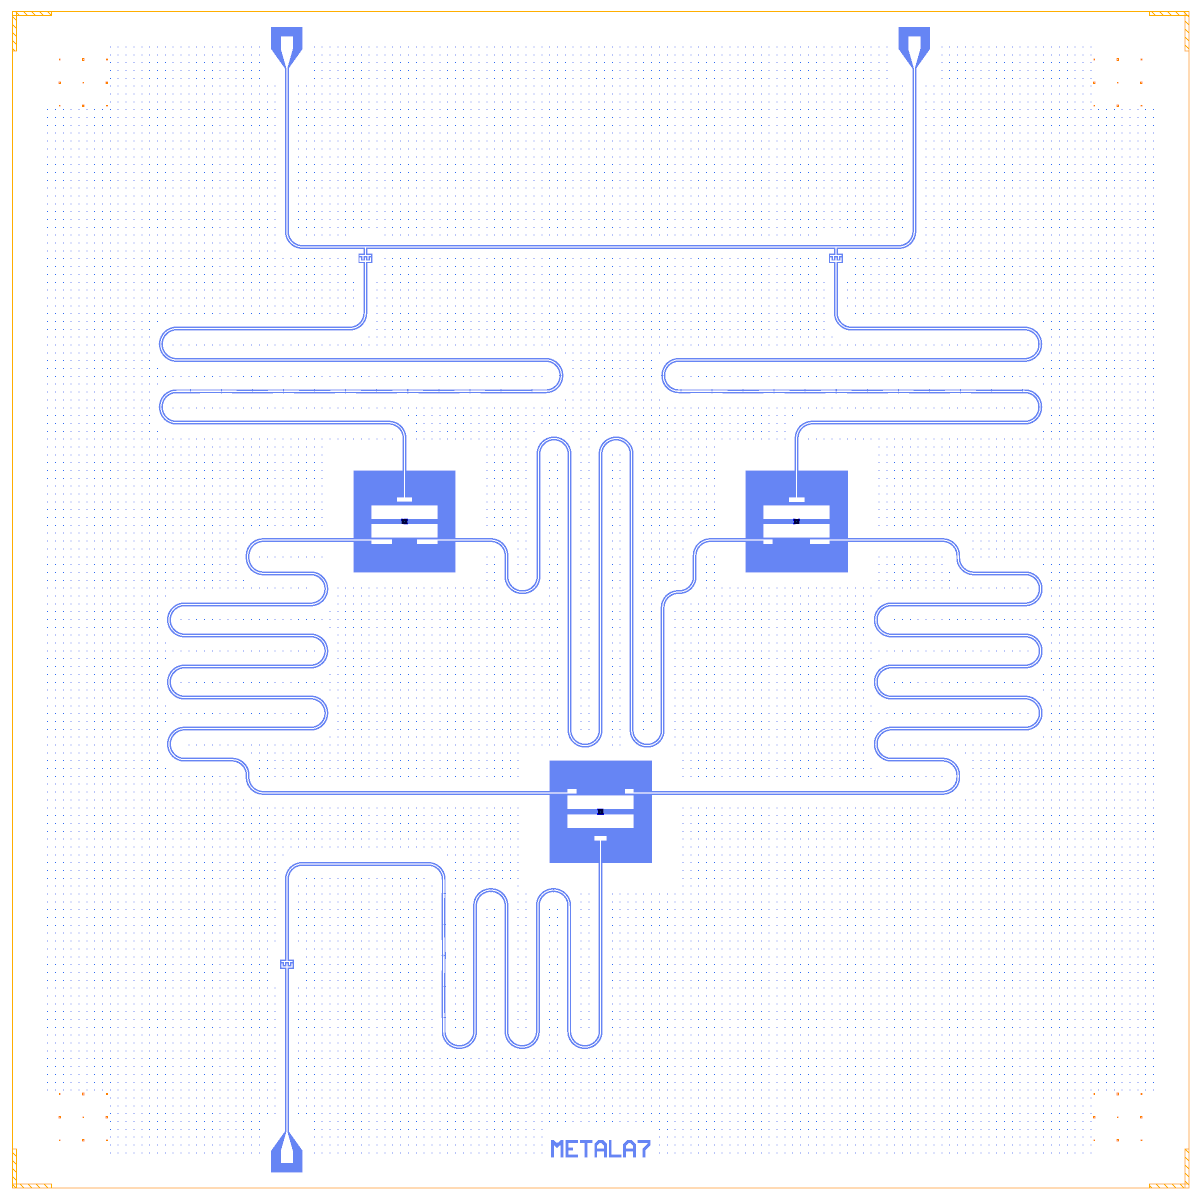

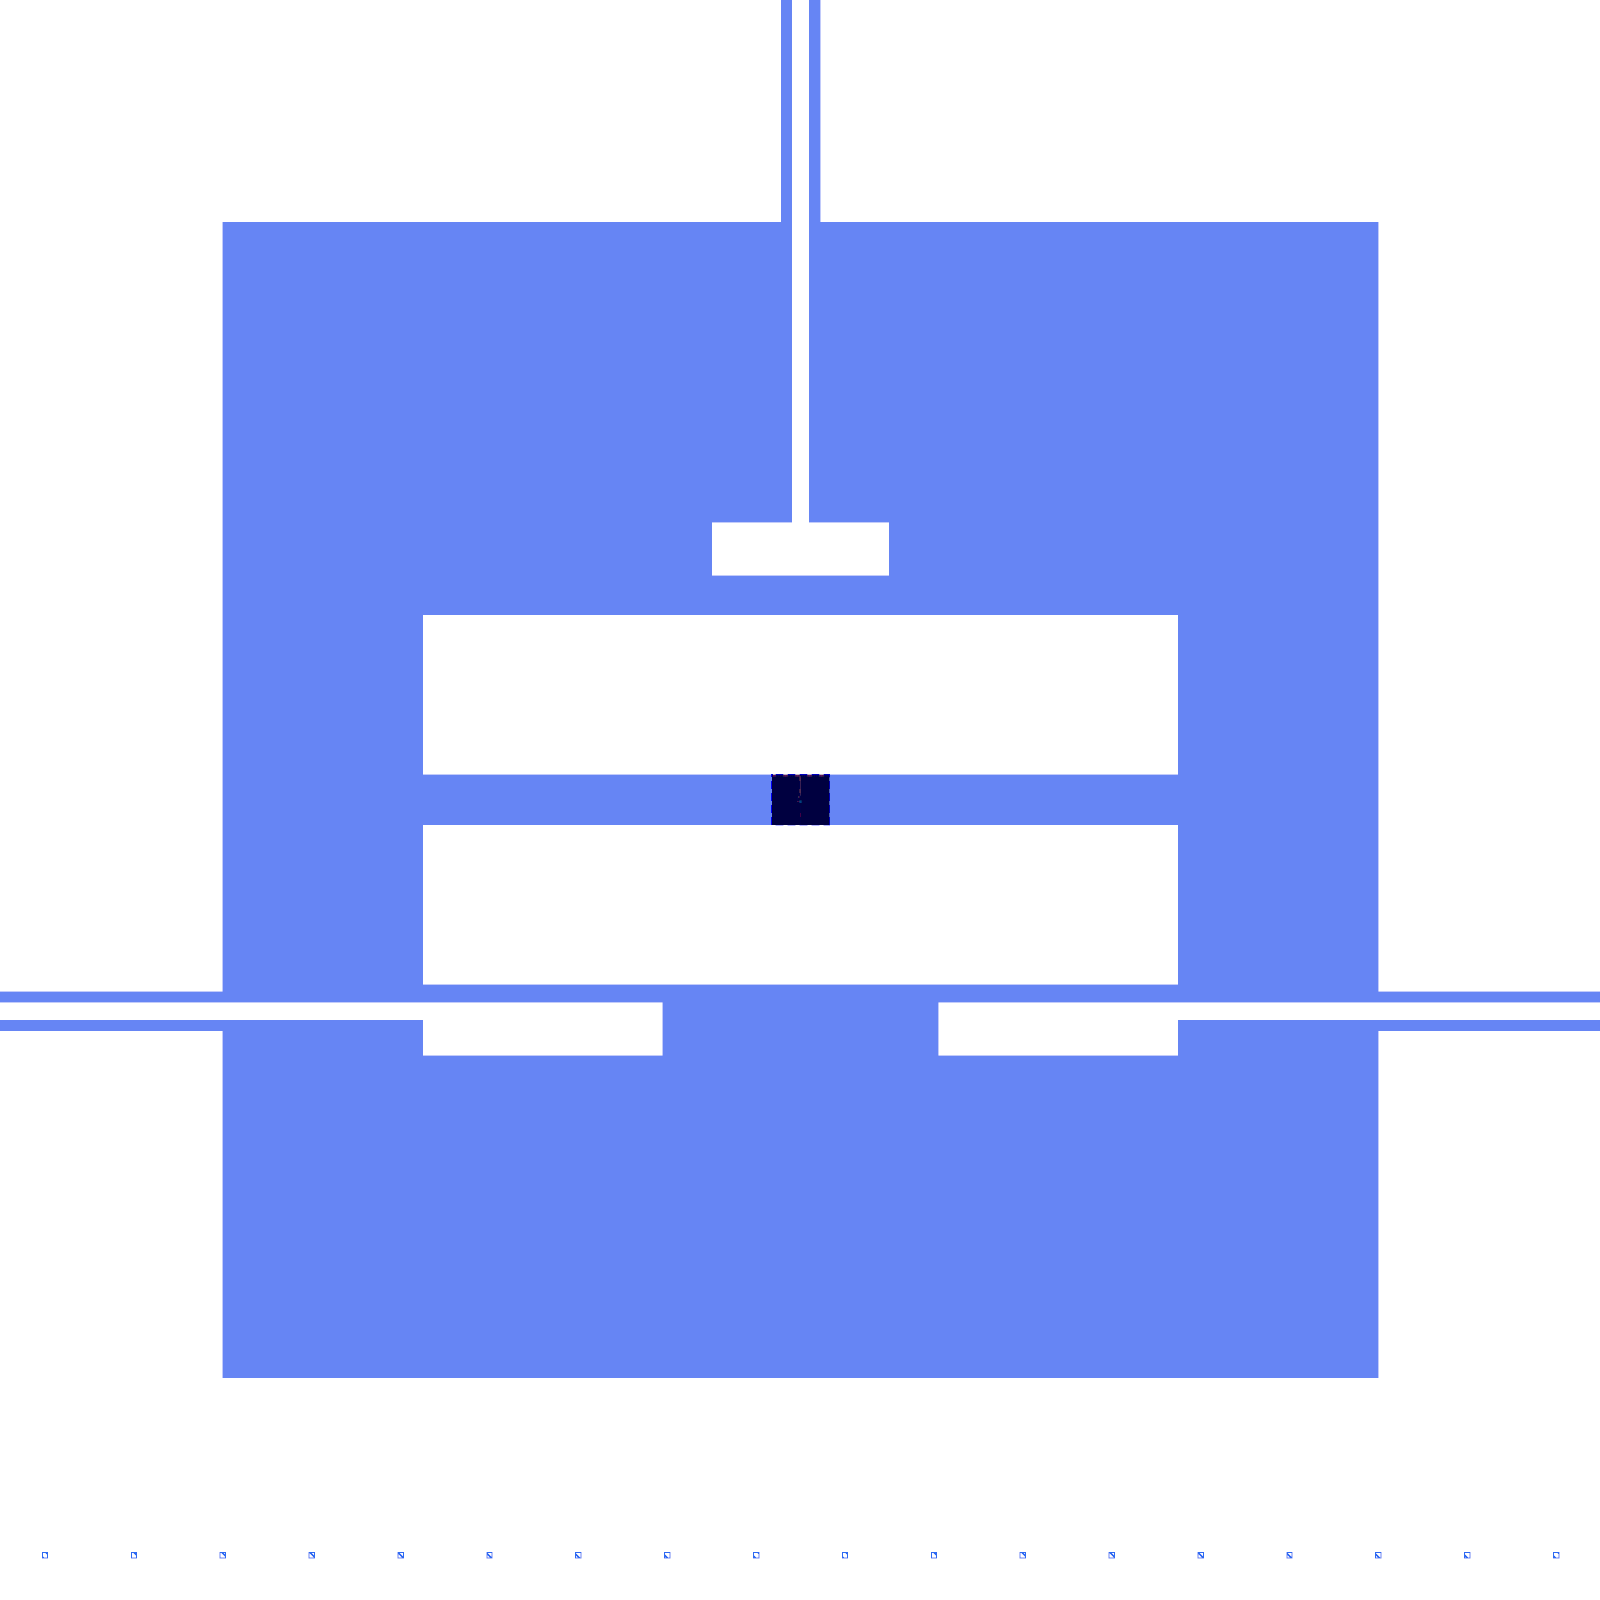

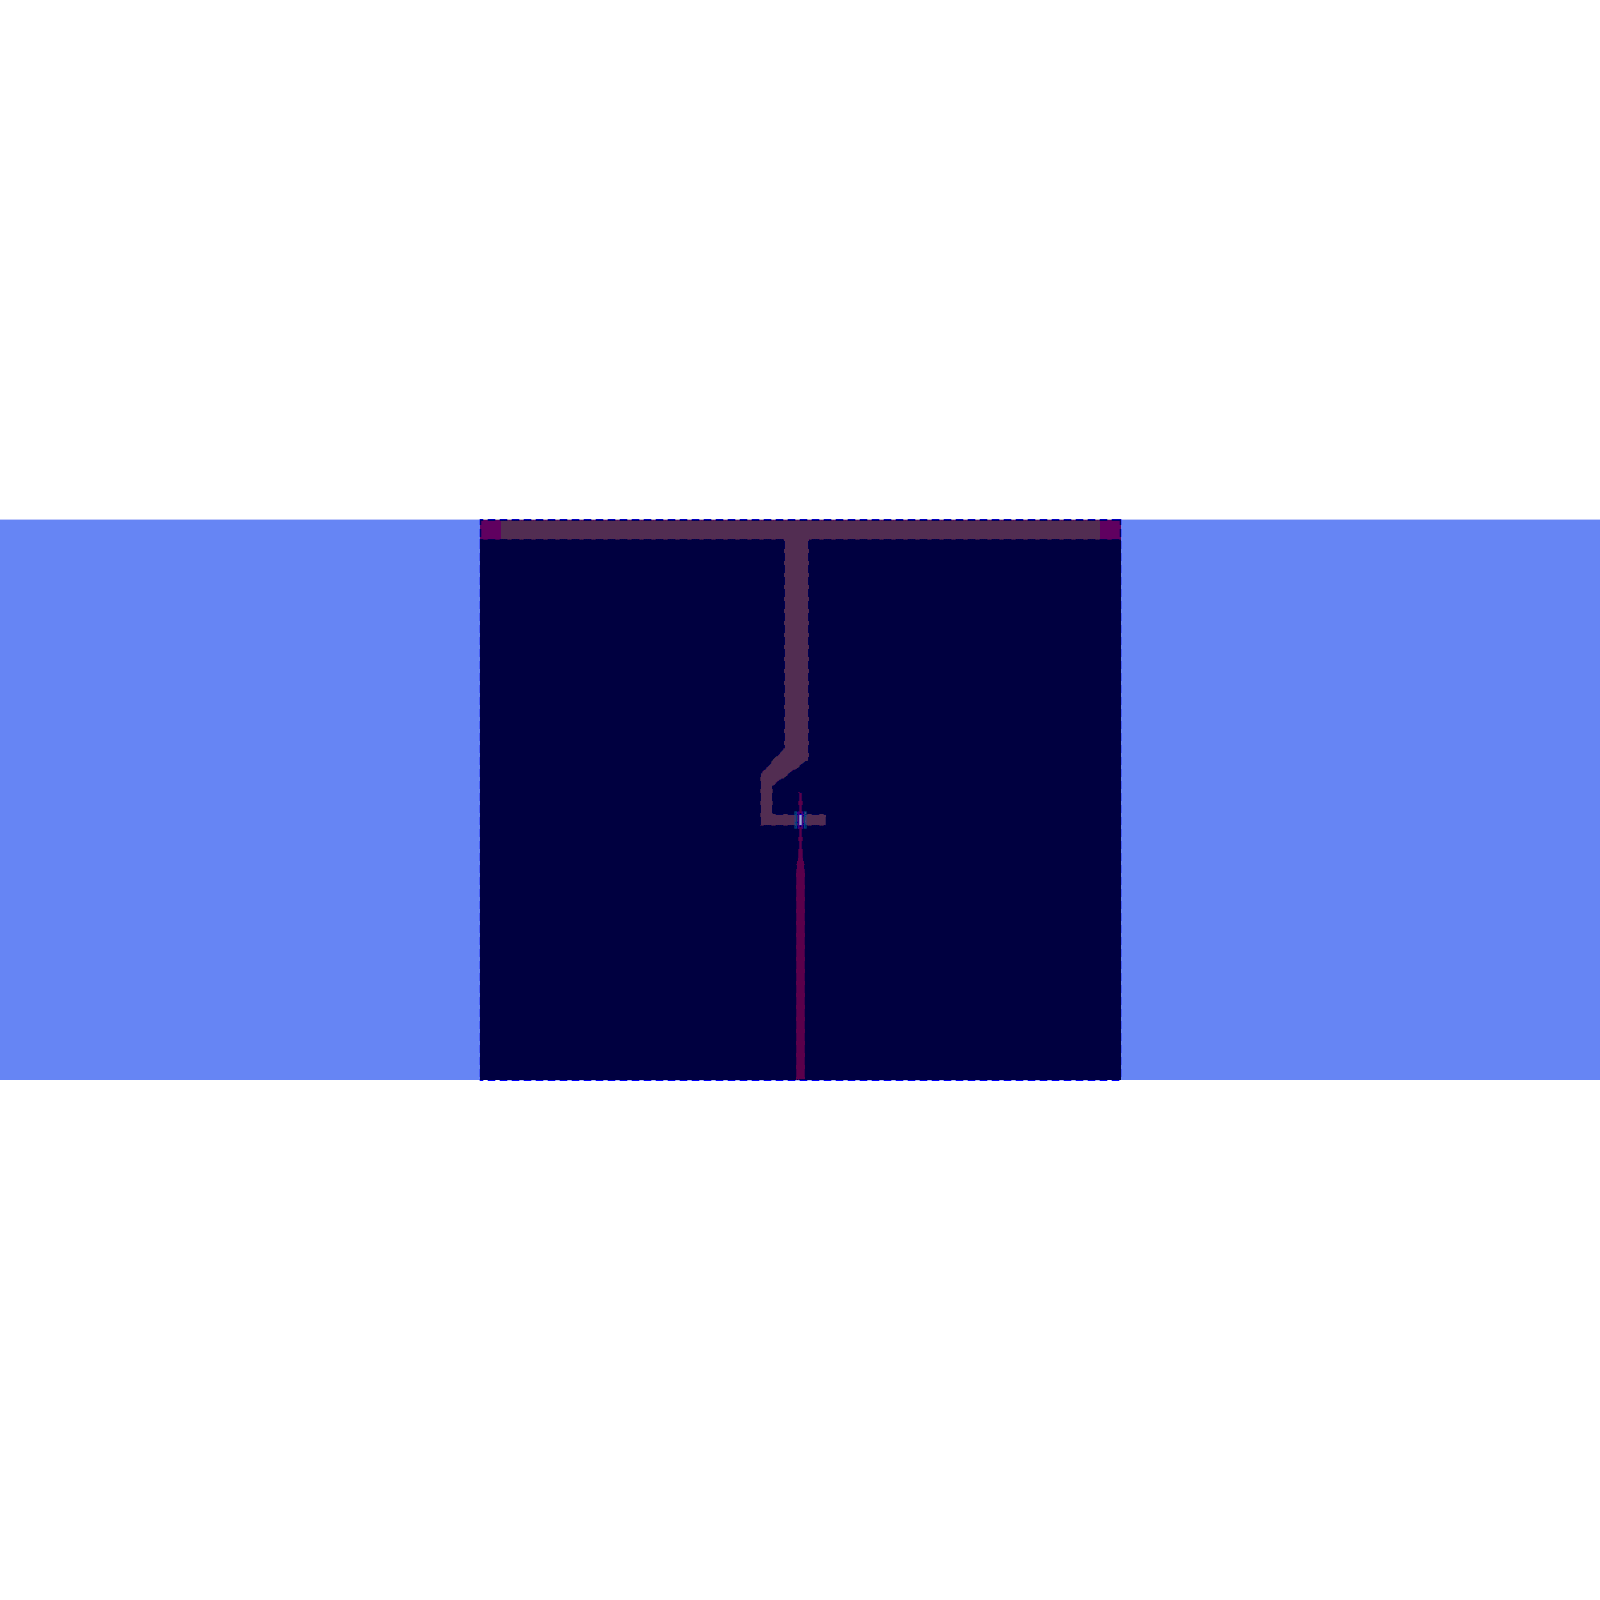

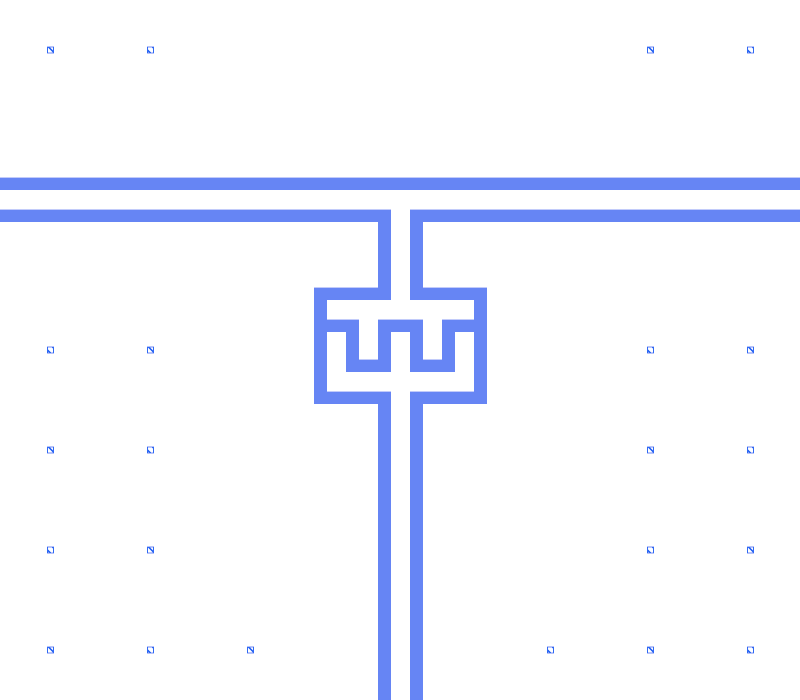

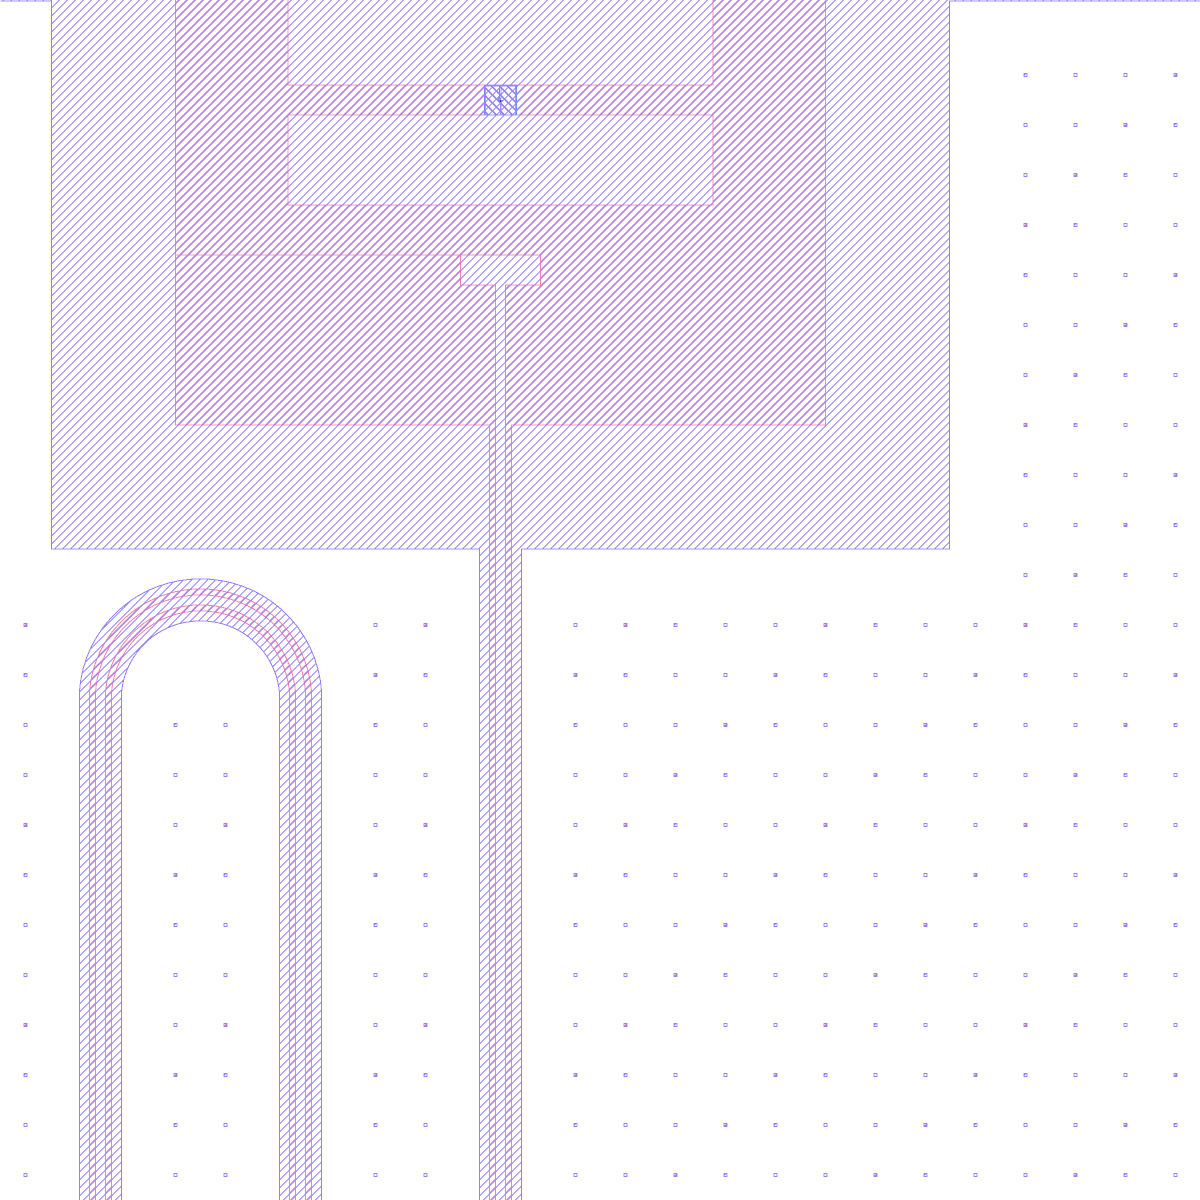

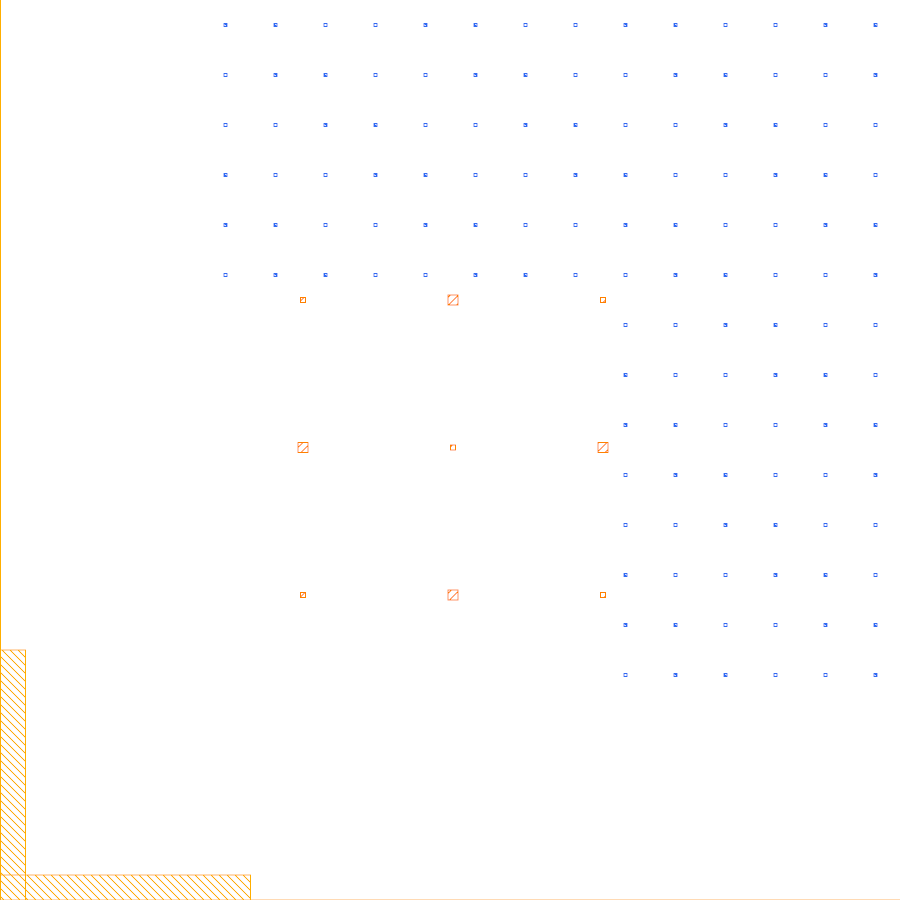

In [16]:
QX, QY = d.data["instances"]["Q_0"]["place"]["at"]
TX, TY = d.data["instances"]["Cap_Readout_Q_0"]["place"]["at"]
show_snapshot(d, OUT / "a7_ims2022_3q.png", size=(1200, 1200))
show_snapshot(d, OUT / "a7_ims2022_3q_q0.png", box=(QX - 450, QY - 450, QX + 450, QY + 450), width=420)
show_snapshot(d, OUT / "a7_ims2022_3q_jj.png", box=(QX - 40, QY - 40, QX + 40, QY + 40), width=300)
show_snapshot(d, OUT / "a7_ims2022_3q_tee.png", box=(TX - 200, TY - 250, TX + 200, TY + 100), size=(800, 700), width=360)
Q2X, Q2Y = d.data["instances"]["Q_2"]["place"]["at"]   # free ground south-east of Q_2 shows the 3 µm holes
snap_file(Path("build") / "a7_ims2022_3q_fab.oas", OUT / "a7_ims2022_3q_cheese.png",
          box=(Q2X - 500, Q2Y - 1100, Q2X + 700, Q2Y + 100), size=(1200, 1200), width=420)
show_snapshot(d, OUT / "a7_ims2022_3q_frame.png", box=(-750, -750, 150, 150), size=(900, 900), width=300);

## 16 · Summary

| | |
|---|---|
| matches the source | every Metal component with the tuned options, their positions, the route end pins and tuned lengths (buses 9550 / 9350 / 9700 µm, readouts 8800 / 8500 / 8300 µm), all stated targets |
| PDK changes | the 7.5 mm Quantcore die with the QCT frame; sapphire stack; the three launchpads 100 µm from the north / south edges (were 990 µm); trilayer junctions sized for 4.8 / 5.0 / 5.2 GHz; cheese = the original's 3 µm Metal cheese, drawn by the build; content centred (no shift needed) |
| differs | the bus / readout meander shapes (qcc router); LOM f_q 4.84 / 5.02 / 5.20 GHz on the 4.8 / 5.0 / 5.2 GHz targets, α −374 / −382 / −418 MHz (target −300), readouts 6.88 / 7.11 / 7.24 GHz (targets 6.8 / 7.0 / 7.2; χ −1.26 / −1.31 / −0.56 MHz), buses 6.24 / 6.36 / 6.15 GHz in the bus groups (targets 5.8 / 6.0 / 6.2), static ZZ 22 / 81 / 37 kHz |
| PDK design warnings | 3 × `pdk_rn` (R_n ≈ 98–102 kΩ, sized for the source's targets) |
| open | the Q3D jobs are exported, not solved (`RUN_FEM = False`) |